#### Import libraries

In [564]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import make_scorer, matthews_corrcoef


RANDOM_STATE = 42


sns.set_theme(style="whitegrid", palette="muted")

#### Load dataset

In [528]:
train = pd.read_csv("../data/Mobile_Price_Prediction_train.csv")
test = pd.read_csv("../data/Mobile_Price_Prediction_test.csv")

print(f"Train: {train.shape} | Test: {test.shape}")

Train: (2000, 22) | Test: (1000, 24)


In [529]:
train.head()

,id,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,1,707,No,2.1,Yes,2,0,25,0.8,Med,...,495,574,3838,9,2,7,1,No,Yes,3
1,2,1218,No,1.8,Yes,1,1,14,0.5,Med,...,229,616,398,17,0,5,1,No,No,0
2,3,1986,No,0.5,No,7,0,51,0.4,Low,...,342,774,3165,5,0,13,1,No,No,3
3,4,1290,No,0.5,No,0,0,3,0.1,Med,...,600,1109,1214,9,8,15,0,Yes,Yes,1
4,5,1135,Yes,2.8,Yes,9,0,43,0.4,Med,...,690,1589,3204,18,13,6,1,No,No,3


In [530]:
test.head()

,id,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,...,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,Unnamed: 21,Unnamed: 22,Unnamed: 23
0,1,1043,Yes,1.8,Yes,14,0,5,0.1,High,...,3476,12,7,2,0,Yes,No,NaN,NaN,NaN
1,2,841,Yes,0.5,Yes,4,1,61,0.8,High,...,3895,6,0,7,1,No,No,NaN,NaN,NaN
2,3,1807,Yes,2.8,No,1,0,27,0.9,High,...,2396,17,10,10,0,Yes,Yes,NaN,,NaN
3,4,1546,No,0.5,Yes,18,1,25,0.5,Low,...,3893,10,0,7,1,Yes,No,NaN,NaN,NaN
4,5,1434,No,1.4,No,11,1,49,0.5,Low,...,1773,15,8,7,1,No,Yes,NaN,NaN,NaN


#### Feature Description

**Attributes**  
| Type | Columns |
| --------------------- | ---------------------------------------------------------------|
| Numeric |  `id`, `battery_power`, `clock_speed`, `fc`, `four_g`, `int_memory`, `m_dep`, `n_cores`, `pc`, `px_height`, `px_width`, `ram`, `sc_h`, `sc_w`, `talk_time`, `three_g`, `price_range` |
| Categorical (nominal) | `blue`, `dual_sim`, `touch_screen`, `wifi` |
| Categorical (ordinal) | `mobile_wt` {Low < Med < High} |
| **Target** | `price_range` = 0 / 1 / 2 / 3 | 

#### Data Quality Audit  
Check types, missing values, duplicates, impossible values and how the categories are spelled before any modelling.

In [531]:
audit = pd.DataFrame({
    "dtype": train.dtypes,
    "missing": train.isna().sum(),
    "n_unique": train.nunique(),
    "example": train.iloc[0]
})

display(audit)
print(f"Missing values in total: {int(train.isna().sum().sum())}")
print(f"Fully duplicated rows: {int(train.duplicated().sum())}")

,dtype,missing,n_unique,example
id,int64,0,2000,1
battery_power,int64,0,1094,707
blue,str,0,2,No
clock_speed,float64,0,26,2.1
dual_sim,str,0,2,Yes
fc,int64,0,20,2
four_g,int64,0,2,0
int_memory,int64,0,63,25
m_dep,float64,0,10,0.8
mobile_wt,str,0,3,Med


Missing values in total: 0
Fully duplicated rows: 0


In [532]:
num_cols_all = [c for c in train.select_dtypes("number").columns if c not in ["id", "price_range"]]
cat_cols_all = [c for c in train.columns if c not in num_cols_all if c not in ["id", "price_range"]]

print(f"Numeric columns: {num_cols_all}")
print(f"Categorical columns: {cat_cols_all}\n")

# Convert categorical plain strings to objects {robust for imputers/ encoders}
for c in cat_cols_all:
    train[c] = train[c].astype(object)

# List the values of categorical features
for c in cat_cols_all:
    print(f"{c:15s} {train[c].value_counts().to_dict()}")

print("\n Numeric ranges:")
display(train[num_cols_all].describe().T)

Numeric columns: ['battery_power', 'clock_speed', 'fc', 'four_g', 'int_memory', 'm_dep', 'n_cores', 'pc', 'px_height', 'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time', 'three_g']
Categorical columns: ['blue', 'dual_sim', 'mobile_wt', 'touch_screen', 'wifi']

blue            {'No': 1010, 'Yes': 990}
dual_sim        {'Yes': 1019, 'No': 981}
mobile_wt       {'Med': 826, 'Low': 678, 'High': 496}
touch_screen    {'Yes': 1006, 'No': 994}
wifi            {'Yes': 1014, 'No': 986}

 Numeric ranges:


,count,mean,std,min,25%,50%,75%,max
battery_power,2000.0,1238.51850,439.418206,501.0,851.75,1226.0,1615.25,1998.0
clock_speed,2000.0,1.52225,0.816004,0.5,0.70,1.5,2.20,3.0
fc,2000.0,4.30950,4.341444,0.0,1.00,3.0,7.00,19.0
four_g,2000.0,0.52150,0.499662,0.0,0.00,1.0,1.00,1.0
int_memory,2000.0,32.04650,18.145715,2.0,16.00,32.0,48.00,64.0
m_dep,2000.0,0.50175,0.288416,0.1,0.20,0.5,0.80,1.0
n_cores,2000.0,4.52050,2.287837,1.0,3.00,4.0,7.00,8.0
pc,2000.0,9.91650,6.064315,0.0,5.00,10.0,15.00,20.0
px_height,2000.0,645.10800,443.780811,0.0,282.75,564.0,947.25,1960.0
px_width,2000.0,1251.51550,432.199447,500.0,874.75,1247.0,1633.00,1998.0


**What the audit tells us**: The train dataset has no misssing values and no duplicates, so no rows are dropped. Categories are consistent. Numeric ranges are plausible.

#### Exploratory Data Analysis

##### Target

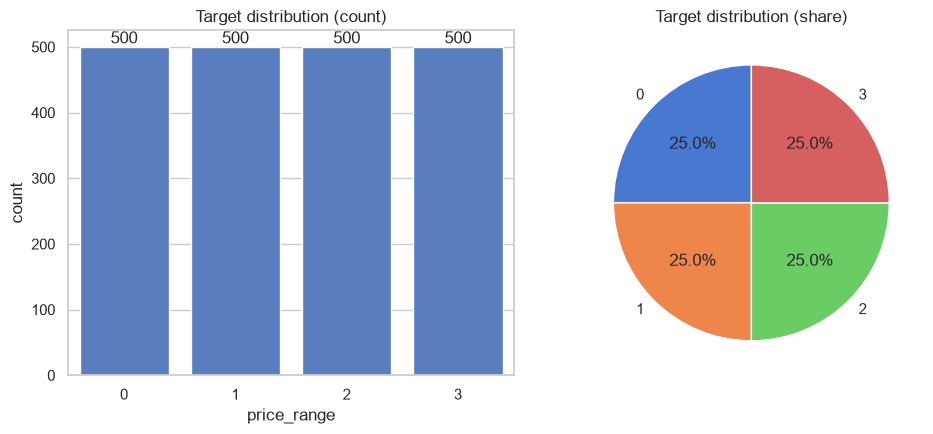

Target distribution: {0: 500, 1: 500, 2: 500, 3: 500}


In [533]:
vc = train["price_range"].value_counts().sort_index().to_dict()

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))

sns.countplot(data=train, x="price_range", ax=ax[0])
ax[0].set_title("Target distribution (count)")
ax[0].bar_label(ax[0].containers[0])

ax[1].pie(x=list(vc.values()), labels=list(vc.keys()), autopct="%1.1f%%", startangle=90)
ax[1].set_title("Target distribution (share)")

plt.tight_layout()
plt.show()

print(f"Target distribution: {vc}")

The target variable `price_range` is evenly distributed accross all four classes with 500 samples (25%) in each category. The dataset does not exhibit class imbalance and no class-balancing techniques are required.

##### Statistical Summary

In [534]:
print("Summary of numeric columns: ")
display(train[num_cols_all].describe().T)

print("\nSummary of categorical columns: ")
display(train[cat_cols_all].describe().T)

for c in cat_cols_all:
    print(f"{c:15s} {train[c].value_counts().to_dict()}")

Summary of numeric columns: 


,count,mean,std,min,25%,50%,75%,max
battery_power,2000.0,1238.51850,439.418206,501.0,851.75,1226.0,1615.25,1998.0
clock_speed,2000.0,1.52225,0.816004,0.5,0.70,1.5,2.20,3.0
fc,2000.0,4.30950,4.341444,0.0,1.00,3.0,7.00,19.0
four_g,2000.0,0.52150,0.499662,0.0,0.00,1.0,1.00,1.0
int_memory,2000.0,32.04650,18.145715,2.0,16.00,32.0,48.00,64.0
m_dep,2000.0,0.50175,0.288416,0.1,0.20,0.5,0.80,1.0
n_cores,2000.0,4.52050,2.287837,1.0,3.00,4.0,7.00,8.0
pc,2000.0,9.91650,6.064315,0.0,5.00,10.0,15.00,20.0
px_height,2000.0,645.10800,443.780811,0.0,282.75,564.0,947.25,1960.0
px_width,2000.0,1251.51550,432.199447,500.0,874.75,1247.0,1633.00,1998.0



Summary of categorical columns: 


,count,unique,top,freq
blue,2000,2,No,1010
dual_sim,2000,2,Yes,1019
mobile_wt,2000,3,Med,826
touch_screen,2000,2,Yes,1006
wifi,2000,2,Yes,1014


blue            {'No': 1010, 'Yes': 990}
dual_sim        {'Yes': 1019, 'No': 981}
mobile_wt       {'Med': 826, 'Low': 678, 'High': 496}
touch_screen    {'Yes': 1006, 'No': 994}
wifi            {'Yes': 1014, 'No': 986}


##### Univariate Analysis

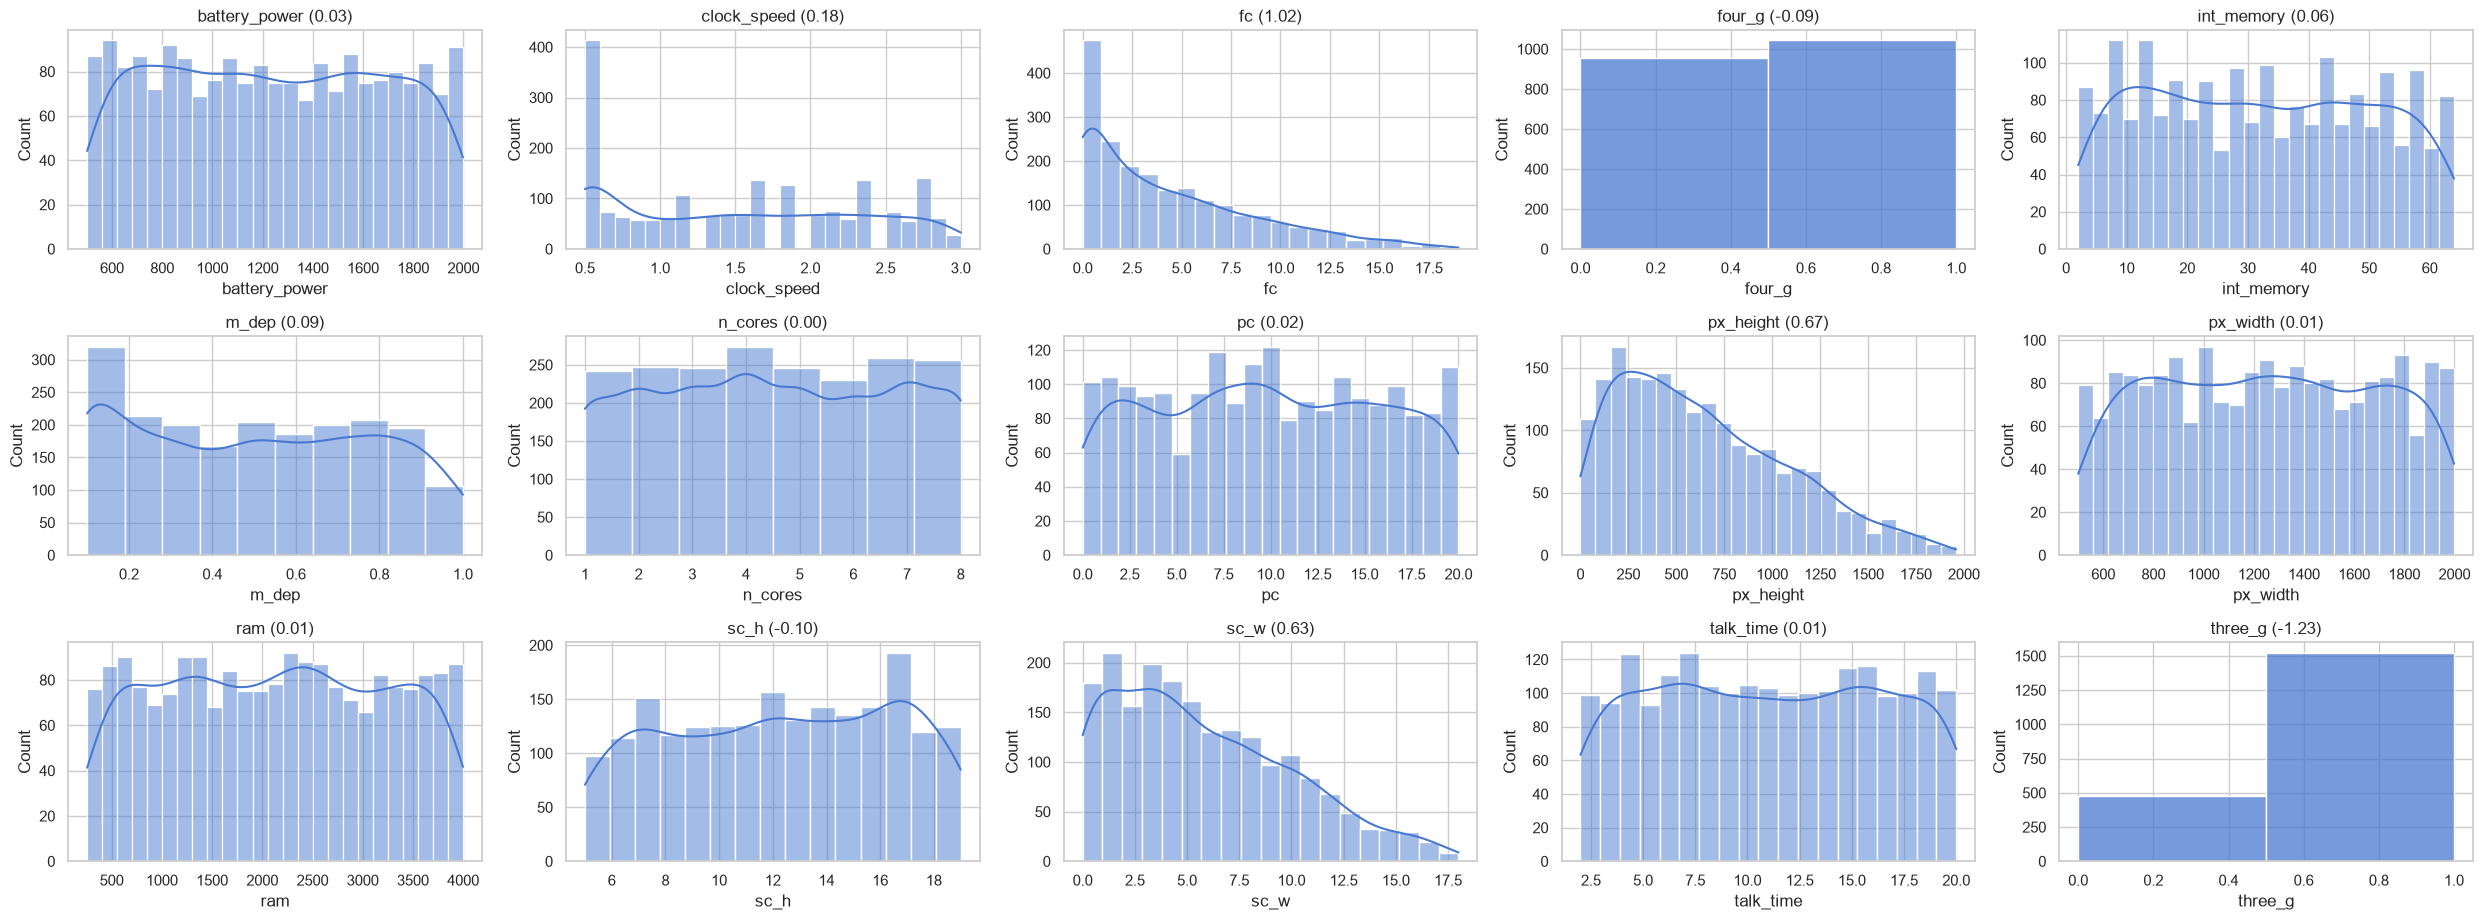

In [535]:
# Plot histograms for all numeric features

fig, axes = plt.subplots(5, 5, figsize=(25, 15))
axes = axes.flatten()

for i, c in enumerate(num_cols_all):
    sns.histplot(
        data=train,
        x=c,
        kde=c not in ["three_g", "four_g"],
        ax=axes[i],
        bins=25 if train[c].nunique() > 25 else train[c].nunique()
    )

    axes[i].set_title(f"{c} ({train[c].skew():.2f})")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

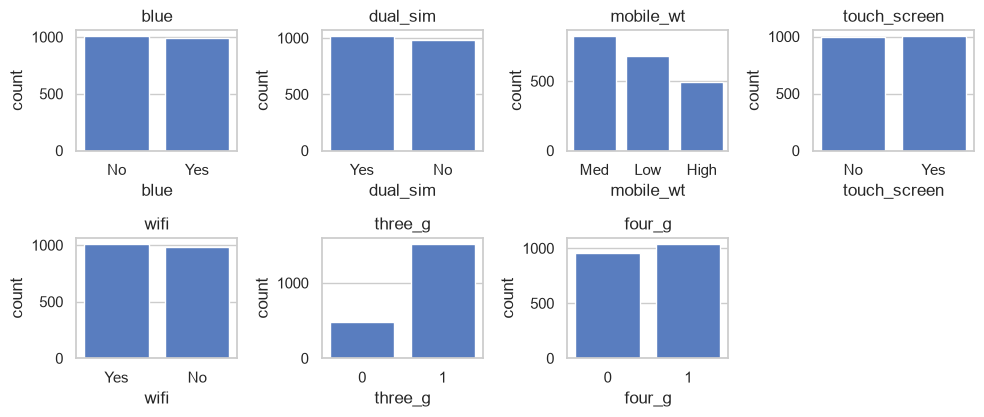

In [536]:
# Plot countplots for all categorical features
cols = cat_cols_all + ["three_g", "four_g"]

fig, axes = plt.subplots(4, 4, figsize=(10, 8))
axes = axes.flatten()

for i, c in enumerate(cols):
    sns.countplot(data=train, x=c, ax=axes[i])
    axes[i].set_title(f"{c}")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

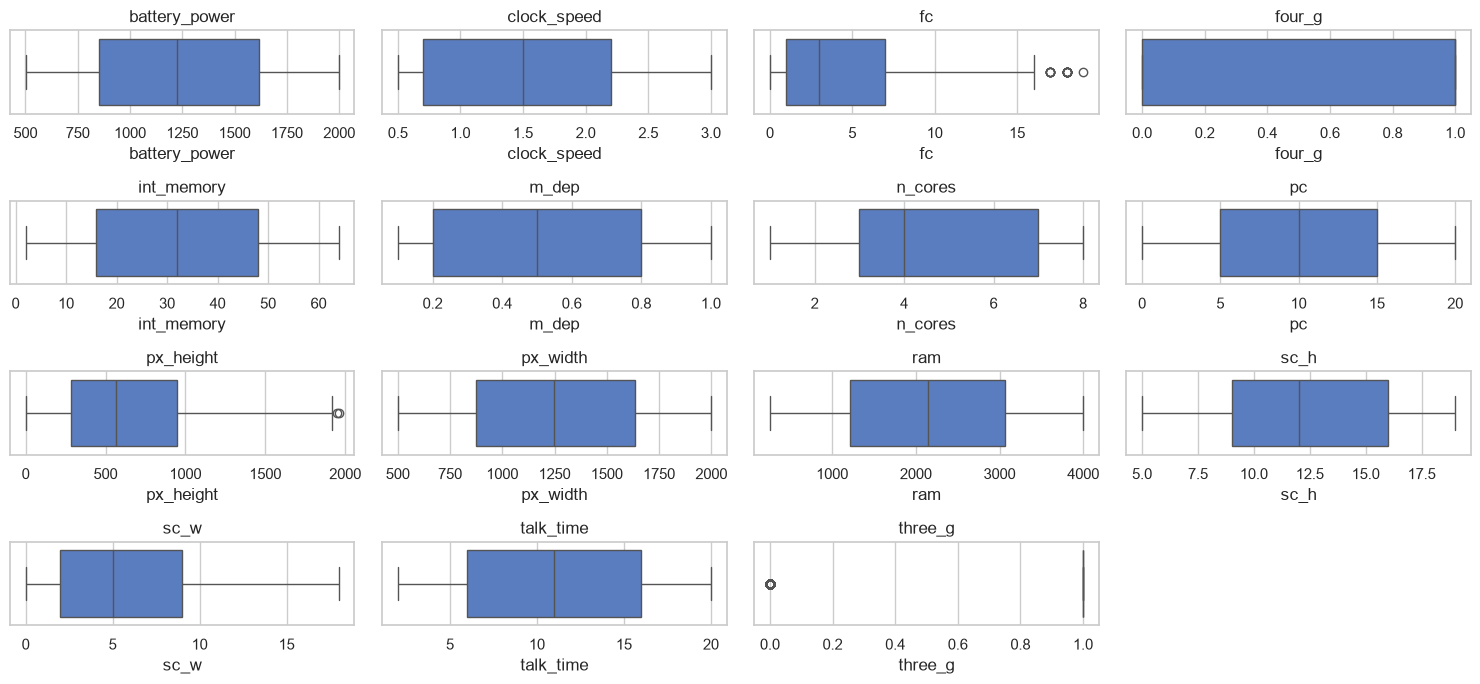

In [537]:
# Plot boxplots for outlier identification accross all numerical features
fig, axes = plt.subplots(4, 4, figsize=(15, 7))
axes = axes.flatten()

for i, c in enumerate(num_cols_all):
    sns.boxplot(data=train, x=c, ax=axes[i])
    axes[i].set_title(c)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

##### Bivariate Analysis

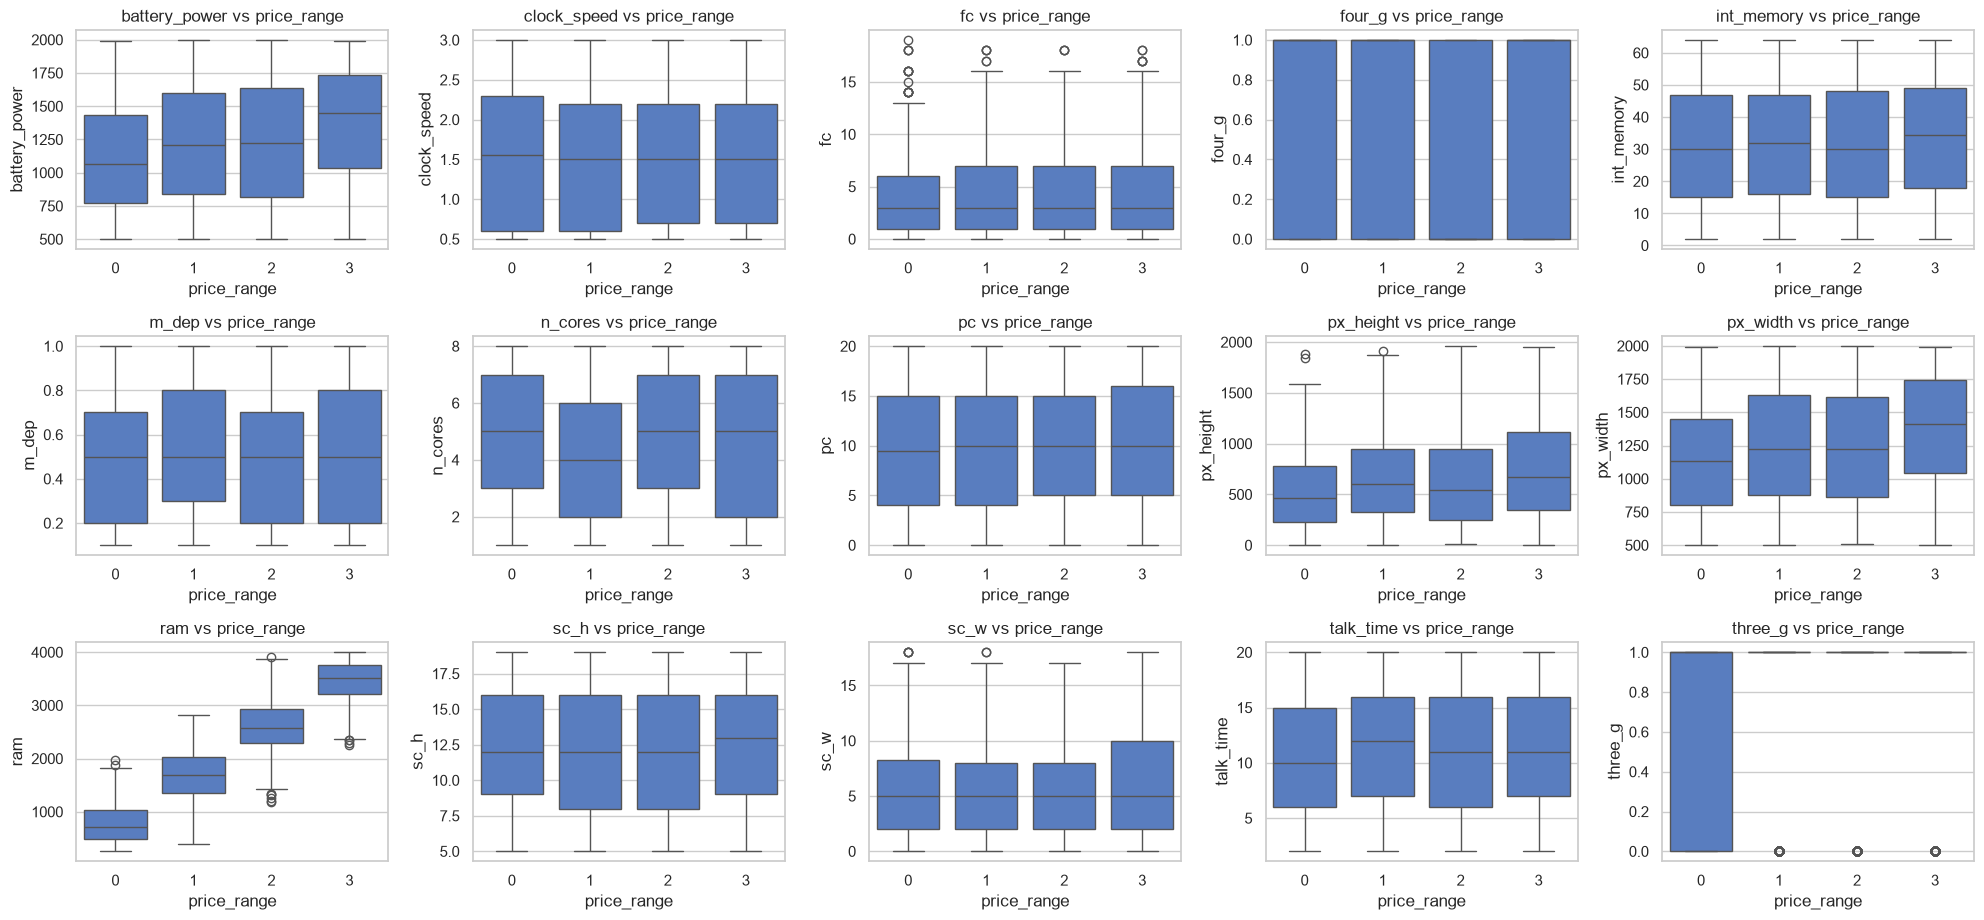

In [538]:
# Plot boxplots for all numeric features against the target
fig, axes = plt.subplots(5, 5, figsize=(20, 15))
axes = axes.flatten()

for i, c in enumerate(num_cols_all):
    sns.boxplot(data=train, x="price_range", y=c, ax=axes[i])
    axes[i].set_title(f"{c} vs price_range")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

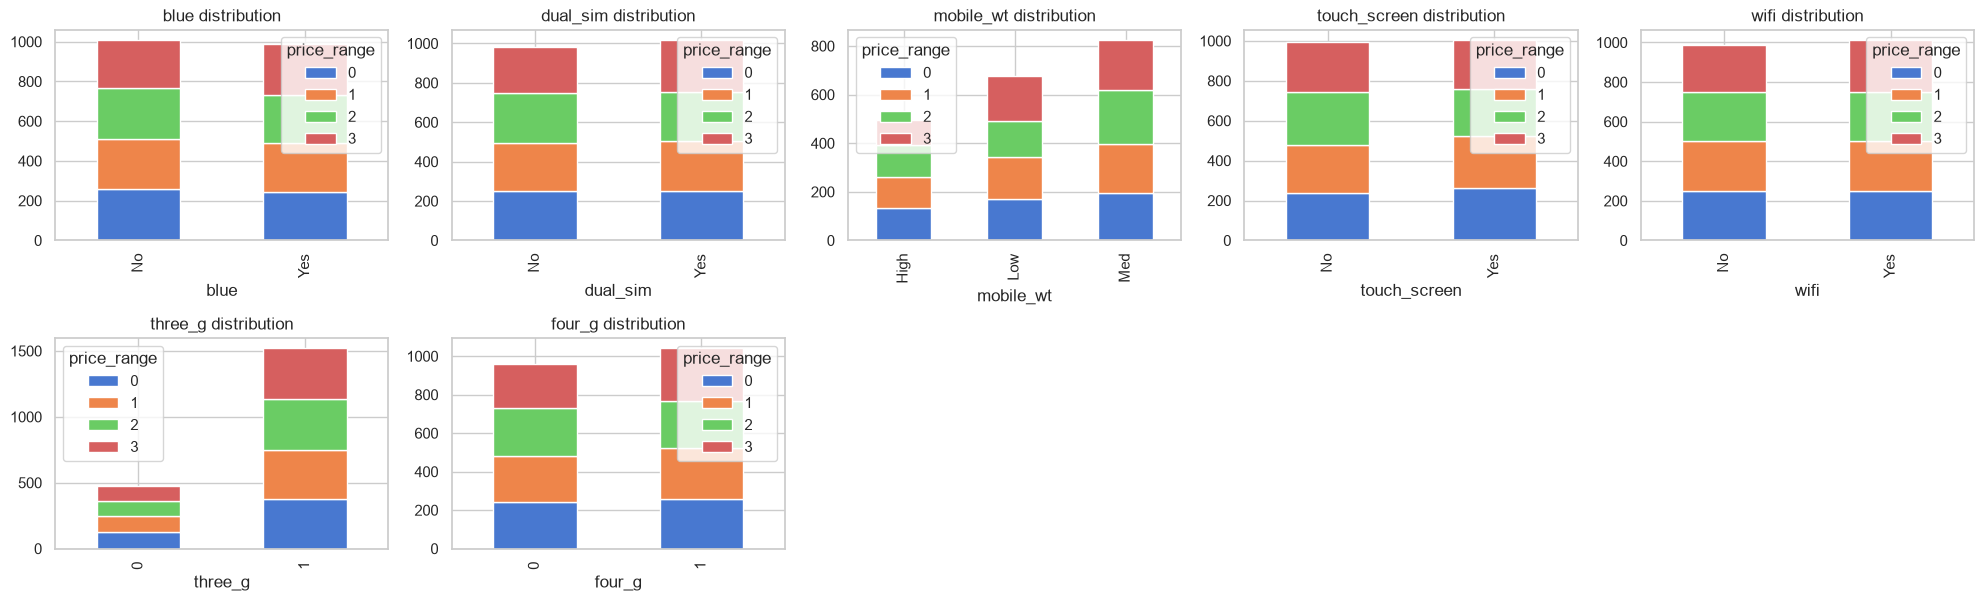

In [539]:
# Plot countplots for all categorical features against the target
cols = cat_cols_all + ["three_g", "four_g"]
fig, axes = plt.subplots(5, 5, figsize=(20, 15))
axes = axes.flatten()

for i, c in enumerate(cols):
    pd.crosstab(train[c], train["price_range"]).plot(kind="bar", stacked=True, ax=axes[i])
    axes[i].set_title(f"{c} distribution")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

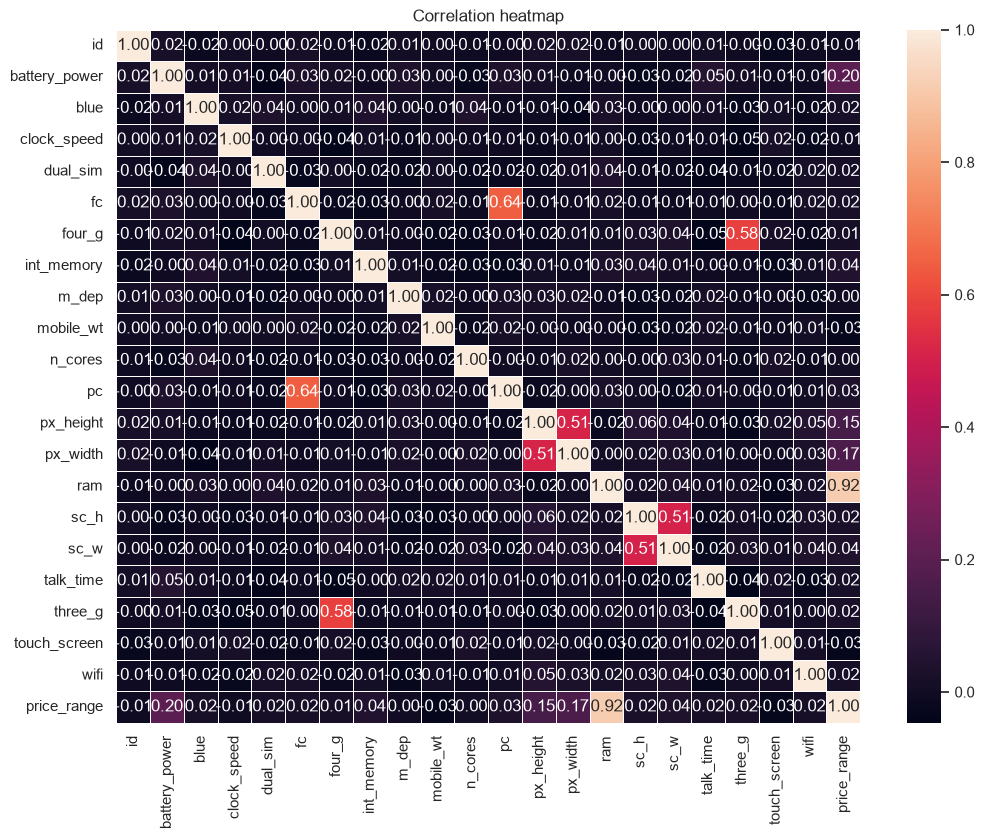

ram              0.917
battery_power    0.201
px_width         0.166
px_height        0.149
int_memory       0.044
sc_w             0.039
pc               0.034
three_g          0.024
sc_h             0.023
fc               0.022
talk_time        0.022
blue             0.021
wifi             0.019
dual_sim         0.017
four_g           0.015
n_cores          0.004
m_dep            0.001
id              -0.006
clock_speed     -0.007
touch_screen    -0.030
mobile_wt       -0.031
Name: price_range, dtype: float64

In [540]:
# Correlation heatmap
df = train.copy()

for c in cat_cols_all:
    if c != "mobile_wt":
        df[c] = df[c].map({"No": 0, "Yes": 1})

df["mobile_wt"] = df["mobile_wt"].map({"Low": 0, "Med": 1, "High": 2})

corr = df.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", linewidths=0.5)
plt.title("Correlation heatmap")
plt.show()

display(corr["price_range"].drop("price_range").round(3).sort_values(ascending=False))


### Data Pre-Processing

#### Drop irrelevant features

In [541]:
train = train.drop(["id"], axis=1)
test = test.drop(["Unnamed: 21", "Unnamed: 22", "Unnamed: 23"], axis=1)

#### Check missing, duplicate values

In [542]:
print(f"{"Train":5s} : Missing: {int(train.isna().sum().sum())}, Duplicates: {int(train.duplicated().sum())}")
print(f"{"Test":5s} : Missing: {int(test.isna().sum().sum())}, Duplicates: {int(test.duplicated().sum())}")

Train : Missing: 0, Duplicates: 0
Test  : Missing: 0, Duplicates: 0


#### Outlier and Skew Detection for Numerical Features

In [543]:
num_cols_all = [c for c in train.select_dtypes(include="number").columns if c not in ["price_range"]]
cat_cols_all = [c for c in train.select_dtypes(exclude="number").columns]

In [544]:
q1, q3 = train[num_cols_all].quantile(0.25), train[num_cols_all].quantile(0.75)
iqr = q3 - q1

out = ((train[num_cols_all] < q1 - 1.5 * iqr) | (train[num_cols_all] > q3 + 1.5 * iqr)).sum()
skw = train[num_cols_all].skew()

display(pd.DataFrame({"Outliers": out, "Skew": skw.round(2)}))

,Outliers,Skew
battery_power,0,0.03
clock_speed,0,0.18
fc,18,1.02
four_g,0,-0.09
int_memory,0,0.06
m_dep,0,0.09
n_cores,0,0.00
pc,0,0.02
px_height,2,0.67
px_width,0,0.01


### Feature Engineering

| Feature | Definition | Why |
| -------------------- | ------------------------------------| -----------------------------------------|
| `fc` | `log1p` | tame the right-skew for linear/ distance-based models |
| `px_area` | `px_height` * `px_width` | total pixels |
| `screen_area` | `sc_h` * `sc_w` | screen size |
| `cam_px` | `fc` + `pc` | total camera megapixels |  

Unordered/ Nominal categorical features are **one-hot encoded** in the pipeline. Label encoding them would let distance-models treat categories as if they are ordered.

In [545]:
def engineer(d):
    d = d.copy()
    d["fc_log"] = np.log1p(d["fc"])
    d["px_area"] = d["px_height"] * d["px_width"]
    d["screen_area"] = d["sc_h"] * d["sc_w"]
    d["cam_px"] = d["fc_log"] + d["pc"]
    return d.replace([np.inf, -np.inf], np.nan)

fe = engineer(train)
new_features = ["fc_log", "px_area", "screen_area", "cam_px"]
display(fe[new_features].describe().T.round(2))

print("Skew before and after log transformation:")
print(pd.DataFrame({"raw": round(float(fe["fc"].skew()), 2), "log": round(float(fe["fc_log"].skew()), 2)}, index=["fc"]))

,count,mean,std,min,25%,50%,75%,max
fc_log,2000.0,1.29,0.92,0.0,0.69,1.39,2.08,3.0
px_area,2000.0,905260.05,829762.50,0.0,263200.50,601359.00,1359027.25,3886306.0
screen_area,2000.0,80.26,76.82,0.0,19.00,55.00,121.50,342.0
cam_px,2000.0,11.21,6.70,0.0,5.62,11.10,17.00,23.0


Skew before and after log transformation:
     raw   log
fc  1.02 -0.12


In [546]:
print(new_features)

['fc_log', 'px_area', 'screen_area', 'cam_px']


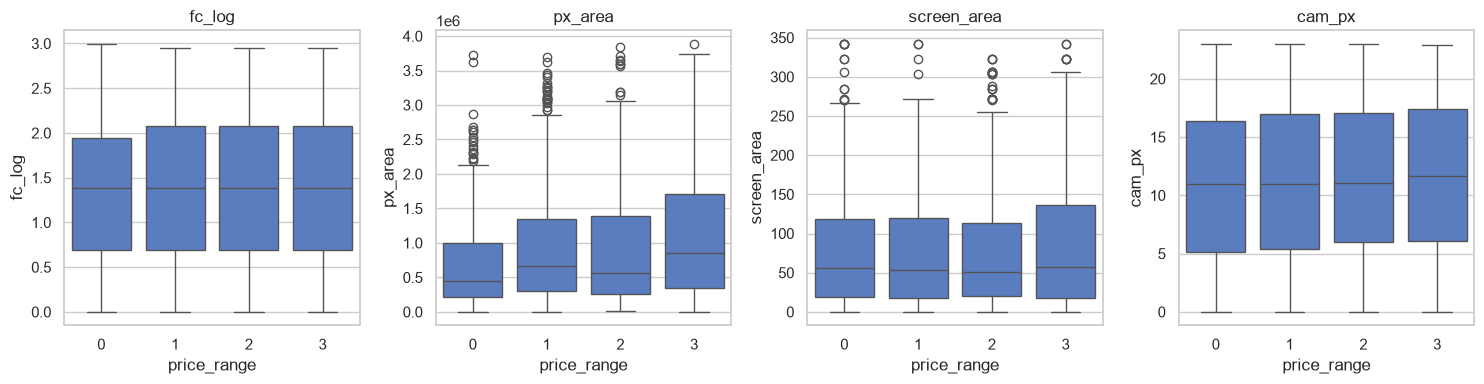

In [547]:
# Do the new features carry signal?
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

for ax, c in zip(axes, new_features):
    sns.boxplot(data=fe, x="price_range", y=c, ax=ax)
    ax.set_title(c)

plt.tight_layout()
plt.show()

### Preprocessing pipeline and train/test split

In [548]:
num_cols = [c for c in fe.select_dtypes(include="number").columns if c not in ["price_range"]]
cat_cols = [c for c in fe.select_dtypes(exclude="number").columns]

X = fe[num_cols + cat_cols]
y = fe["price_range"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

def make_prep(scaler):
    num = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", scaler)])
    cat = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False))])
    
    return ColumnTransformer([("num", num, num_cols), ("cat", cat, cat_cols)])

prep_std = lambda: make_prep(StandardScaler())
prep_mm = lambda: make_prep(MinMaxScaler(clip=True))

n_out = prep_std().fit(X_train).transform(X_train).shape[1]
print(f"{len(num_cols)} numeric + {len(cat_cols)} categorical columns = {n_out} model inputs after one-hot encoding")

Train: (1600, 24), Test: (400, 24)
19 numeric + 5 categorical columns = 26 model inputs after one-hot encoding


Imputers, scaler and encoder are fitted inside each cross-validation fold (they sit in the `Pipeline`). Standard scaling is used for most models and MinMax for the Naive Bayes variants that need non-negative inputs.

### Model comparison (Cross-validated)

In [568]:
def build_models():
    m = {
        "Logistic Regression": Pipeline([("prep", prep_std()), ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]),
        "Decision Tree": Pipeline([("prep", prep_std()), ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
        "KNN": Pipeline([("prep", prep_std()), ("clf", KNeighborsClassifier())]),
        "Gaussian NB": Pipeline([("prep", prep_std()), ("clf", GaussianNB())]),
        "Multinomial NB": Pipeline([("prep", prep_mm()), ("clf", MultinomialNB())]),
        "SVM": Pipeline([("prep", prep_std()), ("clf", CalibratedClassifierCV(SVC(), ensemble=False))])
    }
    return m

models = build_models()
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "auc": "roc_auc_ovr", "precision": "precision_macro", "recall": "recall_macro", "f1": "f1_macro", "mcc": make_scorer(matthews_corrcoef)}

rows, fitted = [], {}
for name, pipe in models.items():
    cvr = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1, return_train_score=True)
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    pred = pipe.predict(X_test)
    rows.append({"Model": name,
                 "Accuracy": cvr["test_accuracy"].mean(),
                 "AUC": cvr["test_auc"].mean(),
                 "Precision": cvr["test_precision"].mean(),
                 "Recall": cvr["test_recall"].mean(),
                 "F1": cvr["test_f1"].mean(),
                 "MCC": cvr["test_mcc"].mean()})
results = pd.DataFrame(rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)
display(results.round(3).style.background_gradient(subset=["Accuracy", "F1"], cmap="Blues"))


,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.945000,0.996000,0.946000,0.945000,0.945000,0.927000
1,SVM,0.858000,0.952000,0.861000,0.858000,0.858000,0.810000
2,Decision Tree,0.826000,0.884000,0.828000,0.826000,0.826000,0.768000
3,Gaussian NB,0.795000,0.945000,0.799000,0.795000,0.796000,0.727000
4,KNN,0.545000,0.778000,0.560000,0.545000,0.548000,0.396000
5,Multinomial NB,0.534000,0.776000,0.569000,0.534000,0.539000,0.386000
